# Lab: Macro-level structure and synthetic models

<a href="../downloads/lab_04.ipynb"
   class="btn btn-outline-primary"
   download>
  Download notebook (.ipynb)
</a>

This lab combines the two parts of this week's content: measures of macro-level structures and synthetic network models. The objective is to compute the measures on one of the networks that you produced during the previous labs (e.g. a retweet network) and also on the corresponding synthetic networks produced using different models based on different network generation mechanisms. The expected final result of this lab is a table with the different networks as rows and the different measures as columns, allowing you to reflect about the models that best describe your empirical network and possible mechanisms behind it.

The lab consists of three parts. In the first part you generate networks - the objective is to become familiar with the different synthetic models and their parameters. The second part has two objectives: compute the measures discussed in the theory, and _most importantly_ for each measure compare how it varies across the different networks, reflecting on what you learn from these comparisons. The third part is just the compilation of all your previous results into a summary table, that you can use both to consolidate the different observations and reflections made during the lab and _most importantly (?)_ as a basis for the presentation to the teachers on Friday.

## Contents

- [PART 1: Network generation](#PART-1:-Network-generation)
- [PART 2: Measures](#PART-2:-Measures)
- [PART 3: Summary](#PART-3:-Summary)

## PART 1: Network generation

### Setup: load (or build) the empirical network

Run this cell first. It gives everybody the same starting point from their own local data: the directed, weighted retweet
network of Labs 2-3 (strength >= 50, giant weak component) as `g_dir`. The first run builds it from the files in the data
folder and saves a cache file, so later runs just load it. Delete `retweet_network_filtered.pickle` in the data folder to force a rebuild.

In [2]:
import random
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('../data')                                    # adjust if this notebook sits somewhere else
NCOL = DATA / 'retweet_network.ncol'                      # edge list written in Lab 2
CACHE = DATA / 'retweet_network_filtered.pickle'          # cache of the filtered network
MIN_STRENGTH = 50                                         # same filter as Labs 2-3


def load_filtered_network():
    """Directed, weighted retweet network used in Lab 3: strength >= MIN_STRENGTH, giant weak component.
    Built from the local data on the first run, loaded from the cache afterwards."""
    if CACHE.exists():
        return ig.Graph.Read_Pickle(str(CACHE))
    if not NCOL.exists():                                 # rebuild the edge list from the Lab 1 output, as in Lab 2
        edges_csv = DATA / 'retweet_network_edges.csv'
        if not edges_csv.exists():
            raise FileNotFoundError(f'Neither {NCOL} nor {edges_csv} found: run the Lab 1 build and Lab 2 first, '
                                    f'or fix DATA.')
        edges = pd.read_csv(edges_csv, dtype={'source_account_id': str, 'target_account_id': str,
                                              'unresolved_target_tweet_id': str})
        known = edges.dropna(subset=['target_account_id'])    # an unknown target cannot be a network edge
        pairs = (known.groupby(['source_account_id', 'target_account_id'], as_index=False)['retweet_count']
                      .sum())                                 # one weighted edge per account pair
        pairs.to_csv(NCOL, sep=' ', header=False, index=False)
    g_full = ig.read(NCOL, format='ncol', directed=True)
    g_full.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})   # removes self-loops
    strength = np.array(g_full.strength(mode='all', weights='weight'))            # retweets sent + received
    g_filt = g_full.induced_subgraph(np.where(strength >= MIN_STRENGTH)[0].tolist())
    g_filt = g_filt.connected_components(mode='weak').giant()
    g_filt.write_pickle(str(CACHE))
    return g_filt


g_dir = load_filtered_network()

g = g_dir.as_undirected(mode='collapse')
for attr in g.es.attributes():
    del g.es[attr]
g.simplify()  
print('undirected, unweighted (Labs 2-3):', g.summary())


def show(graph, name, ref=g):
    """Degree distribution of `graph` vs the reference (log-binned density + log-log CCDF) + a few stats."""
    def ccdf(G):
        d = np.sort(np.array(G.degree()))
        y = 1 - np.arange(len(d)) / len(d)          # P(D >= x)
        return d, y

    dmax = max(max(ref.degree()), max(graph.degree()))
    bins = np.logspace(0, np.log10(dmax + 1), 30)   # log-spaced bins (degree >= 1)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    # left: log-binned density on log-log axes
    for G, lab in [(ref, 'g (data)'), (graph, name)]:
        dens, edges = np.histogram([d for d in G.degree() if d > 0], bins=bins, density=True)
        centers = np.sqrt(edges[:-1] * edges[1:])   # geometric bin centres
        mask = dens > 0
        ax[0].loglog(centers[mask], dens[mask], 'o-', ms=4, alpha=0.7, label=lab)
    ax[0].set_xlabel('degree'); ax[0].set_ylabel('density'); ax[0].legend()

    # right: CCDF on log-log axes
    for G, lab in [(ref, 'g (data)'), (graph, name)]:
        x, y = ccdf(G)
        ax[1].loglog(x, y, '.', ms=3, alpha=0.6, label=lab)
    ax[1].set_xlabel('degree'); ax[1].set_ylabel('P(D ≥ x)'); ax[1].legend()

    fig.suptitle(name)
    plt.tight_layout(); plt.show()

    print(f"{name}: n={graph.vcount()}, m={graph.ecount()}, "
          f"mean deg={np.mean(graph.degree()):.1f}, max deg={max(graph.degree())}, "
          f"simple={graph.is_simple()}, connected={graph.is_connected()}")

undirected, unweighted (Labs 2-3): IGRAPH UN-- 5424 116365 -- 
+ attr: name (v)


### Task 1.1

Retrieve one empirical network that you generated during a previous lab and that you want to use today. Store into a variable $g$. Print basic statistics, as a basic validity check.

#### Student workspace

In [3]:
# empirical network = the filtered retweet network of Labs 2-3 (g_dir, loaded in the setup cell above).
# All the synthetic models below are undirected and unweighted, so we compare them with the

n, m = g.vcount(), g.ecount()
k = round(m / n)                                          # edges brought by each new node in the growing models (1.3, 1.5)
print(f'n = {n}, m = {m}, k = round(m/n) = {k}')


def basic_stats(graph):
    deg = np.array(graph.degree())
    return {'nodes': graph.vcount(), 'edges': graph.ecount(),
            'density': round(graph.density(), 5), 'mean degree': round(deg.mean(), 2),
            'max degree': int(deg.max()), 'components': len(graph.connected_components()),
            'simple': graph.is_simple()}


stats = {}                                                # one row per network, filled in as we go
stats['g (empirical)'] = basic_stats(g)
display(pd.DataFrame.from_dict(stats, orient='index'))

n = 5424, m = 116365, k = round(m/n) = 21


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True


#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.2

Produce an ER network of the same order and size of $g$, and store it into a variable $er$. Print basic statistics, as a basic validity check.

#### Tips

- You may consider generating multiple synthetic networks for each model, if you want to chekc robustness. However, in the interest of time, we suggest to start with one network per model, and only add more at the end if you are quick to complete the tasks.

#### Student workspace

,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True


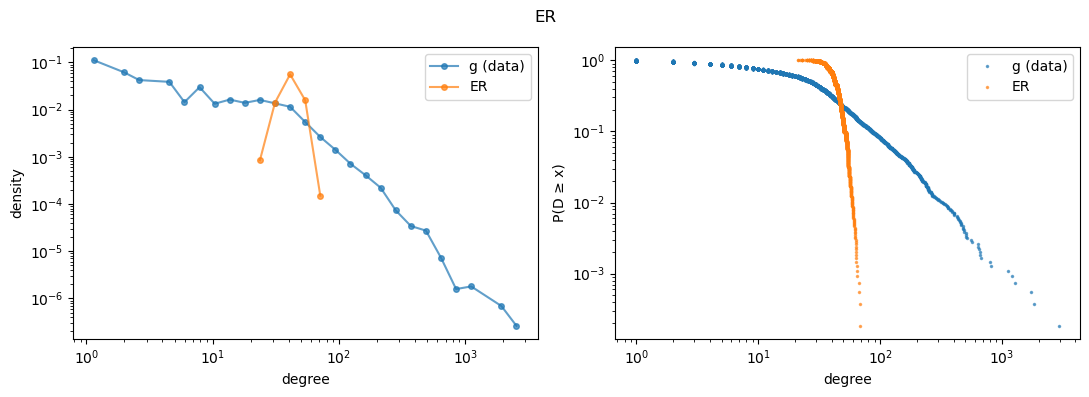

ER: n=5424, m=116365, mean deg=42.9, max deg=68, simple=True, connected=True


In [4]:
random.seed(42)                                           # python-igraph draws from Python's random: reproducible
er = ig.Graph.Erdos_Renyi(n=n, m=m, directed=False, loops=False)    # G(n, m): exactly the same order and size as g
stats['er (ER)'] = basic_stats(er)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(er, "ER")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.3

Produce a network of approximately the same order and size of $g$ as follows: at each timestamp, add one actor to the network and connect it to $k$ randomly chosen existing actors (equal probability). Store the network into a variable $er\_g$ ($er$ refers to the usage of equal probabilities, as in the ER model, while $g$ refers to the fact that this is a growing model, where nodes are added one by one). Print basic statistics, as a basic validity check.

#### NOTES

- This process looks similar to the one followed by the Preferential Attachment model, but with no preference for any of the existing actors.
- Write your own function for this.
- The description above has to be adapted at the beginning of the process, when the number of actors is less than $k$. Choose any simple and reasonable way to make it work.

#### Student workspace

edges: 113673 (expected 113673, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True


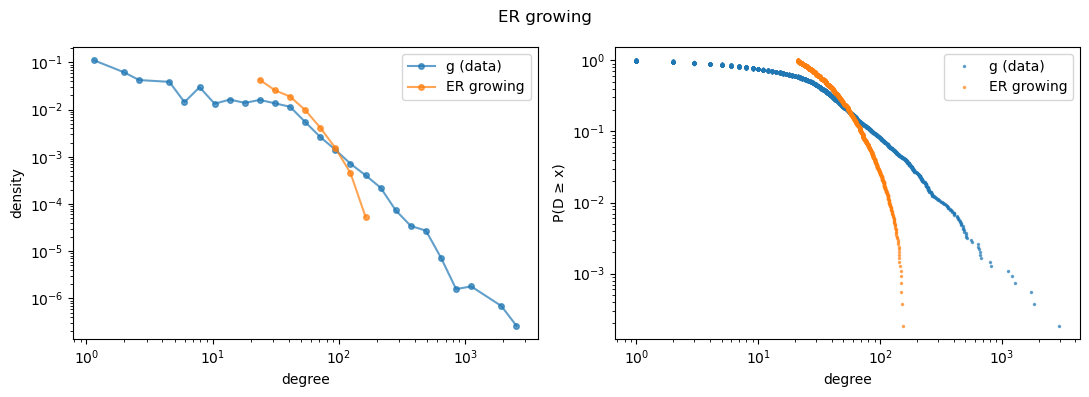

ER growing: n=5424, m=113673, mean deg=41.9, max deg=153, simple=True, connected=True


In [5]:
def generate_er_g(k, n):
    er_g = ig.Graph(n=1)
    for new in range(1,n):
        er_g.add_vertices(1)
        targets = random.sample(range(new), min(k, new))
        er_g.add_edges([(new, t) for t in targets])

    return er_g
        

er_g = generate_er_g(k, n)
# validity check: node number t (t = 1, 2, ...) brings min(t, k) edges
expected = sum(min(t, k) for t in range(1, n))
print(f'edges: {er_g.ecount()} (expected {expected}, target {m}); simple: {er_g.is_simple()}')
stats['er_g (growing ER)'] = basic_stats(er_g)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(er_g, "ER growing")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.4

Produce a configuration model network of approximately the same order and size of $g$, and store it into a variable $cm$. Print basic statistics, as a basic validity check.

#### Student workspace

same degree sequence as g: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True


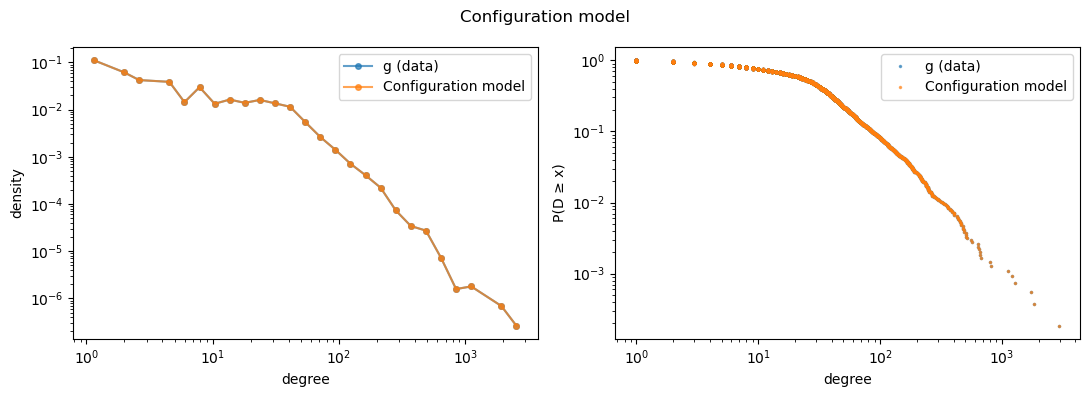

Configuration model: n=5424, m=116365, mean deg=42.9, max deg=2927, simple=True, connected=True


In [6]:
random.seed(42)
# Same degree sequence as g, otherwise random wiring. method='vl' gives a simple (no loops, no multi-edges)
# connected graph; the plain 'configuration' method would create loops and multi-edges, and since g has huge hubs
# many hub-hub edges would be lost when simplifying.
cm = ig.Graph.Degree_Sequence(g.degree(), method='vl')
print('same degree sequence as g:', sorted(cm.degree()) == sorted(g.degree()))
stats['cm (configuration)'] = basic_stats(cm)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(cm, "Configuration model")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.5

Produce a PA (Preferential Attachment) network of approximately the same order and size of $g$, and store it into a variable $pa$. Print basic statistics, as a basic validity check.

#### Student workspace

edges: 113673 (er_g has 113673, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True
pa (preferential attachment),5424,113673,0.00773,41.91,495,1,True


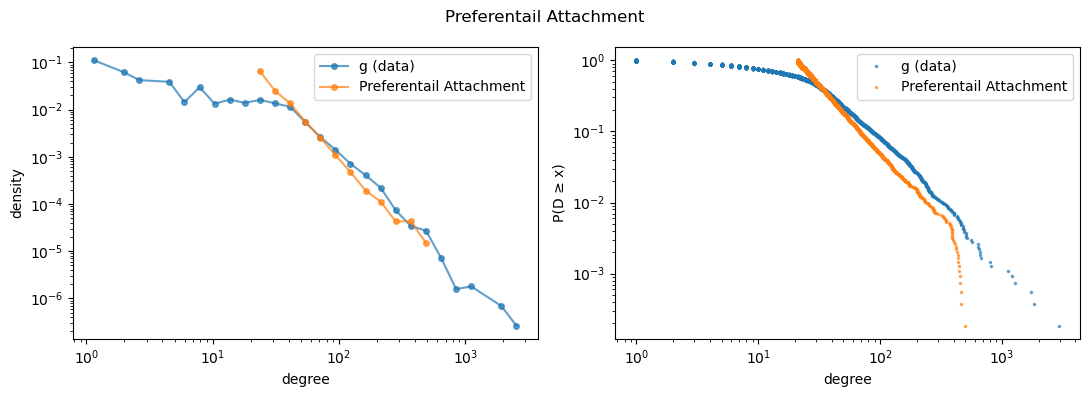

Preferentail Attachment: n=5424, m=113673, mean deg=41.9, max deg=495, simple=True, connected=True


In [7]:
random.seed(42)
# Linear preferential attachment: each new node connects to k existing nodes with probability growing with their degree.
# Same k as er_g, so the only difference between the two is preferential vs. uniform choice.
pa = ig.Graph.Barabasi(n=n, m=k, directed=False, power=1)
print(f'edges: {pa.ecount()} (er_g has {er_g.ecount()}, target {m}); simple: {pa.is_simple()}')
stats['pa (preferential attachment)'] = basic_stats(pa)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(pa, "Preferentail Attachment")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.6

Produce a WS (Watts-Strogatz) network of approximately the same order and size of $g$, and store it into a variable $ws$. Print basic statistics, as a basic validity check.

#### Student workspace

edges: 113904 (expected 113904, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True
pa (preferential attachment),5424,113673,0.00773,41.91,495,1,True
ws (Watts-Strogatz),5424,113904,0.00774,42.00,55,1,True


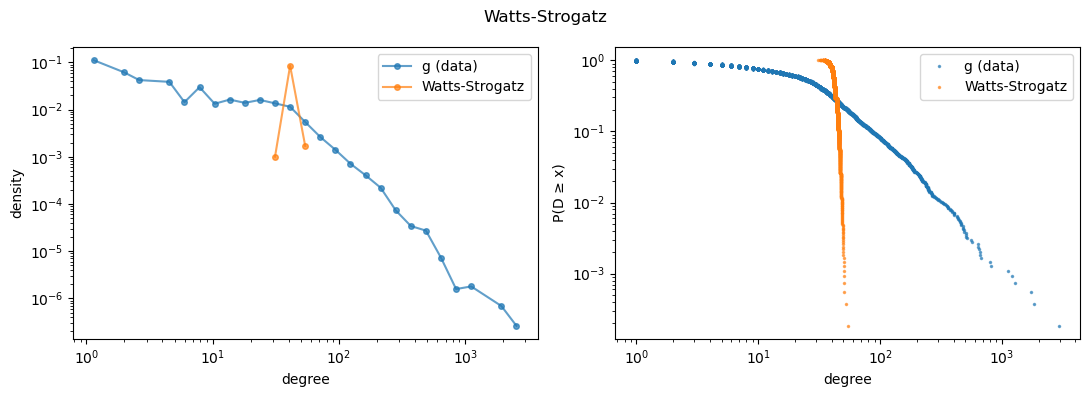

Watts-Strogatz: n=5424, m=113904, mean deg=42.0, max deg=55, simple=True, connected=True


In [8]:
random.seed(42)
# Watts-Strogatz: ring lattice where every node is connected to its `nei` nearest neighbours on each side
# (n * nei edges, so nei = k gives the size of g), then every edge is rewired with probability p.
# A small p keeps the high clustering of the lattice but creates shortcuts (short paths).
p_rewire = 0.1
ws = ig.Graph.Watts_Strogatz(dim=1, size = n, nei = k, p = p_rewire)
print(f'edges: {ws.ecount()} (expected {n * k}, target {m}); simple: {ws.is_simple()}')
stats['ws (Watts-Strogatz)'] = basic_stats(ws)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(ws, "Watts-Strogatz")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.7

Produce a network using a stochastic block model of approximately the same order and size of $g$, and store it into a variable $sbm$. Use the result of a community detection algorithm on $g$ to specify the block number of sizes and the connection probabilities. Print basic statistics, as a basic validity check.

#### Student workspace

Louvain on g: 13 communities, modularity 0.321, sizes [1486, 776, 706, 668, 400, 391, 314, 310, 273, 86, 6, 4, 4]
edges: 116274 (expected 116365, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True
pa (preferential attachment),5424,113673,0.00773,41.91,495,1,True
ws (Watts-Strogatz),5424,113904,0.00774,42.00,55,1,True
sbm (stochastic block model),5424,116274,0.00791,42.87,91,3,True


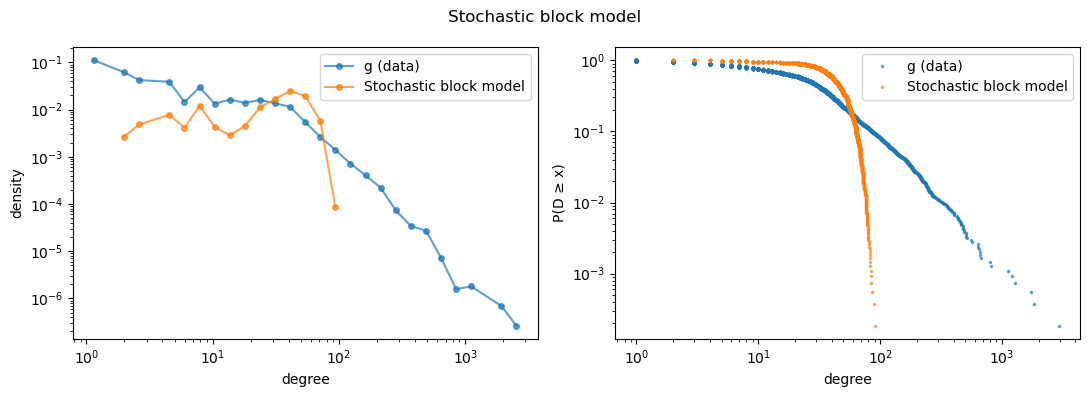

Stochastic block model: n=5424, m=116274, mean deg=42.9, max deg=91, simple=True, connected=False


In [9]:
random.seed(42)
# 1) community detection on g: Louvain (modularity-based, unweighted)
cl = g.community_multilevel(resolution=1.0)
memb = np.array(cl.membership)
B = len(cl)                                               # number of blocks
sizes = np.bincount(memb, minlength=B)                    # block sizes
print(f'Louvain on g: {B} communities, modularity {g.modularity(memb.tolist()):.3f}, sizes {sorted(sizes.tolist(), reverse=True)}')

# 2) number of edges between (and inside) the blocks
el = np.array(g.get_edgelist())
bi, bj = memb[el[:, 0]], memb[el[:, 1]]
E = np.zeros((B, B))
np.add.at(E, (np.minimum(bi, bj), np.maximum(bi, bj)), 1)
E = E + E.T - np.diag(np.diag(E))                         # symmetric; the diagonal = edges inside a block

# 3) connection probability = observed edges / possible edges
possible = np.outer(sizes, sizes).astype(float)           # pairs between block i and block j
np.fill_diagonal(possible, sizes * (sizes - 1) / 2)       # pairs inside a block
pref = np.divide(E, possible, out=np.zeros_like(E), where=possible > 0)

# 4) generate the network (vertices are numbered block by block)
sbm = ig.Graph.SBM(pref.tolist(), sizes.tolist())
sbm.vs['block'] = np.repeat(np.arange(B), sizes).tolist() # planted blocks, useful for Task 2.3

expected_edges = (np.triu(pref) * np.triu(possible)).sum()
print(f'edges: {sbm.ecount()} (expected {expected_edges:.0f}, target {m}); simple: {sbm.is_simple()}')
stats['sbm (stochastic block model)'] = basic_stats(sbm)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(sbm, "Stochastic block model")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

## PART 2: Measures

### Task 2.1

Compute centralisation for all the networks. Feel free to choose the centralisation function(s) to use in this task.

#### TIPS
- For the measures you choose, also produce a plot of their distribution (e.g. degree distribution for degree centralisation). This is useful for face validity, but also to allow you to better understand how the micro-level measure(s) you use to compute centralisation vary in the different networks.

#### Student workspace

star check (should be 1, 1): 1.0 1.0


,degree centralisation,betweenness centralisation
g (empirical),0.5320,0.2784
er (ER),0.0046,0.0005
er_g (growing ER),0.0205,0.0018
cm (configuration),0.5320,0.2372
pa (preferential attachment),0.0836,0.0178
ws (Watts-Strogatz),0.0024,0.0006
sbm (stochastic block model),0.0089,0.0009


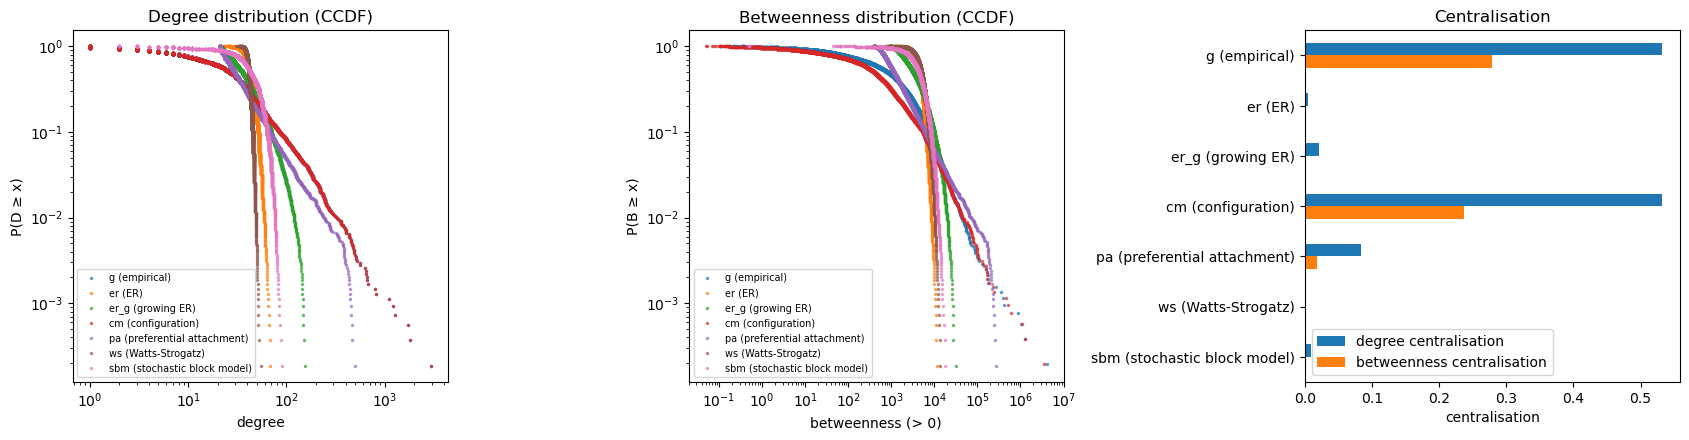

                              max degree  max betweenness
g (empirical)                       2927          4097091
er (ER)                               68            11250
er_g (growing ER)                    153            31153
cm (configuration)                  2927          3490623
pa (preferential attachment)         495           266394
ws (Watts-Strogatz)                   55            13453
sbm (stochastic block model)          91            17714


In [10]:
# Task 2.1: centralisation of all networks (degree + betweenness)

nets = {
    'g (empirical)': g,
    'er (ER)': er,
    'er_g (growing ER)': er_g,
    'cm (configuration)': cm,
    'pa (preferential attachment)': pa,
    'ws (Watts-Strogatz)': ws,
    'sbm (stochastic block model)': sbm,
}


def centralization(values, theoretical_max):
    """Freeman centralisation: sum(max - x_i) / theoretical maximum (the value for a star graph)."""
    values = np.asarray(values, dtype=float)
    return (values.max() - values).sum() / theoretical_max


def degree_centralization(graph):
    N = graph.vcount()
    return centralization(graph.degree(), (N - 1) * (N - 2))


def betweenness_centralization(graph):
    N = graph.vcount()
    b = graph.betweenness(directed=False)                 # raw (unnormalised) betweenness
    return centralization(b, (N - 1) ** 2 * (N - 2) / 2)  # star graph: centre has (N-1)(N-2)/2, others 0


# sanity check on a star graph: both centralisations must be exactly 1
star = ig.Graph.Star(50, mode='undirected')
print('star check (should be 1, 1):',
      round(degree_centralization(star), 3), round(betweenness_centralization(star), 3))

# compute for every network (betweenness may take a little while on the larger networks)
centr = {}
betw = {}                                                 # keep the micro-level values for the plots
for name, G in nets.items():
    betw[name] = np.array(G.betweenness(directed=False))
    centr[name] = {'degree centralisation': degree_centralization(G),
                   'betweenness centralisation': betweenness_centralization(G)}

centr_df = pd.DataFrame.from_dict(centr, orient='index').round(4)
display(centr_df)

# --- plots of the micro-level distributions used for the centralisation ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) degree distribution: CCDF on log-log axes
for name, G in nets.items():
    d = np.sort(np.array(G.degree()))
    y = 1 - np.arange(len(d)) / len(d)                    # P(D >= x)
    ax[0].loglog(d, y, '.', ms=3, alpha=0.6, label=name)
ax[0].set_xlabel('degree'); ax[0].set_ylabel('P(D ≥ x)')
ax[0].set_title('Degree distribution (CCDF)'); ax[0].legend(fontsize=7)

# (b) betweenness distribution: CCDF on log-log axes (nodes with betweenness 0 cannot be shown on a log axis)
for name, b in betw.items():
    b = np.sort(b[b > 0])
    if len(b) == 0:
        continue
    y = 1 - np.arange(len(b)) / len(b)
    ax[1].loglog(b, y, '.', ms=3, alpha=0.6, label=name)
ax[1].set_xlabel('betweenness (> 0)'); ax[1].set_ylabel('P(B ≥ x)')
ax[1].set_title('Betweenness distribution (CCDF)'); ax[1].legend(fontsize=7)

# (c) the resulting centralisation values
centr_df.plot.barh(ax=ax[2])
ax[2].set_xlabel('centralisation'); ax[2].set_title('Centralisation'); ax[2].invert_yaxis()

plt.tight_layout(); plt.show()

# max values explain the centralisation: it is driven by the single most central node
print(pd.DataFrame({'max degree': {n_: max(G.degree()) for n_, G in nets.items()},
                    'max betweenness': {n_: round(b.max()) for n_, b in betw.items()}}))

#### Notes / observations

g has very high degree centralisation (0.49): its top hub has degree 2085, roughly half of all nodes. The homogeneous models (ER, WS, SBM, er_g) are close to 0.
cm matches g exactly (0.4866) because it has the same degree sequence, which is a good validity check.
PA produces hubs, but far too small (max degree 427, centralisation 0.09). Linear preferential attachment doesn't capture how extreme g's hubs are.
er_g is slightly above ER (0.023 vs 0.006), because growth alone makes older nodes accumulate more edges.
Betweenness centralisation follows the same pattern: g 0.27, cm 0.23, PA 0.02, the rest around 0.001. cm reproduces most of it, so the degree sequence is the main driver.

### Task 2.2

Compute cohesion for all the networks. Feel free to choose the cohesion function(s) to use in this task, but use at least average path length and one measure of network-level clustering.

#### Student workspace

,density,avg path length,diameter,global clustering (transitivity),avg local clustering,giant component share,C expected if random,L expected if random
g (empirical),0.0079,2.7409,11,0.0252,0.1081,1.0000,0.0079,2.2874
er (ER),0.0079,2.6986,4,0.0078,0.0078,1.0000,0.0079,2.2874
er_g (growing ER),0.0077,2.7073,4,0.0235,0.0120,1.0000,0.0077,2.3018
cm (configuration),0.0079,2.4477,5,0.0569,0.1426,1.0000,0.0079,2.2874
pa (preferential attachment),0.0077,2.6075,4,0.0304,0.0303,1.0000,0.0077,2.3018
ws (Watts-Strogatz),0.0077,2.9135,4,0.3871,0.3905,1.0000,0.0077,2.3005
sbm (stochastic block model),0.0079,2.7452,6,0.0149,0.0145,0.9985,0.0079,2.2879


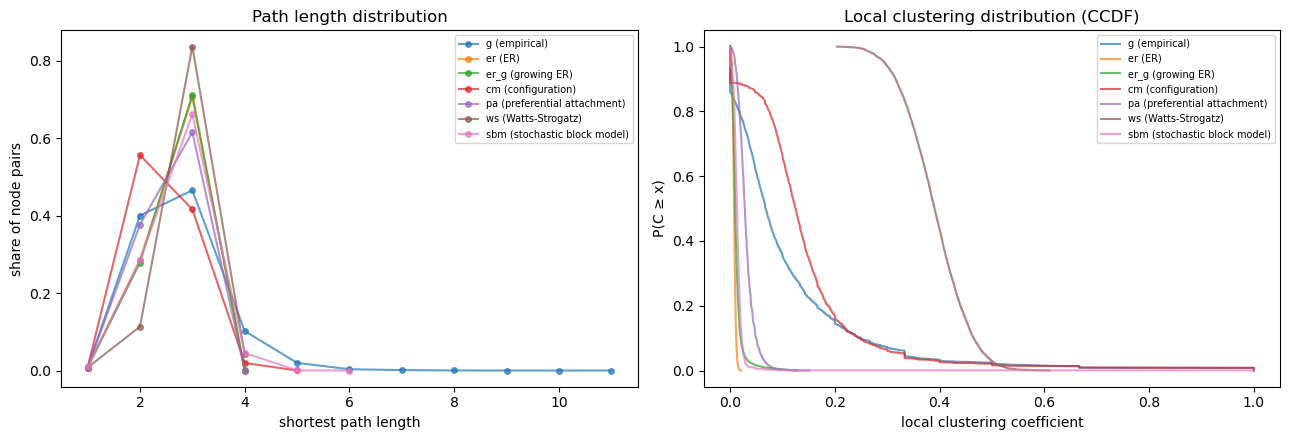

In [11]:
# Task 2.2: cohesion of all networks

def cohesion_measures(graph):
    comps = graph.connected_components()
    giant = comps.giant()
    deg = np.array(graph.degree())
    return {
        'density': graph.density(),
        # paths: unconn=True averages over the pairs that are actually connected (matters if not connected)
        'avg path length': graph.average_path_length(directed=False, unconn=True),
        'diameter': graph.diameter(directed=False, unconn=True),
        # clustering: global (ratio of closed triplets) and average of the local coefficients
        'global clustering (transitivity)': graph.transitivity_undirected(mode='zero'),
        'avg local clustering': graph.transitivity_avglocal_undirected(mode='zero'),
        'giant component share': giant.vcount() / graph.vcount(),
        # random-graph reference values with the same n and mean degree: C ~ <k>/n, L ~ ln n / ln <k>
        'C expected if random': deg.mean() / graph.vcount(),
        'L expected if random': np.log(graph.vcount()) / np.log(deg.mean()),
    }


cohesion = {name: cohesion_measures(G) for name, G in nets.items()}
cohesion_df = pd.DataFrame.from_dict(cohesion, orient='index')
display(cohesion_df.round(4))

# --- distributions behind the measures ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) distribution of shortest path lengths (share of connected pairs at each distance)
for name, G in nets.items():
    h = G.path_length_hist(directed=False)
    lengths = [int(start) for start, end, count in h.bins()]
    counts = np.array([count for start, end, count in h.bins()], dtype=float)
    ax[0].plot(lengths, counts / counts.sum(), 'o-', ms=4, alpha=0.7, label=name)
ax[0].set_xlabel('shortest path length'); ax[0].set_ylabel('share of node pairs')
ax[0].set_title('Path length distribution'); ax[0].legend(fontsize=7)

# (b) distribution of local clustering coefficients (CCDF)
for name, G in nets.items():
    c = np.sort(np.array(G.transitivity_local_undirected(mode='zero')))
    y = 1 - np.arange(len(c)) / len(c)
    ax[1].plot(c, y, '-', alpha=0.7, label=name)
ax[1].set_xlabel('local clustering coefficient'); ax[1].set_ylabel('P(C ≥ x)')
ax[1].set_title('Local clustering distribution (CCDF)'); ax[1].legend(fontsize=7)

plt.tight_layout(); plt.show()

#### Notes / observations

Density is the same everywhere (~0.0086) by construction.
All networks are small worlds in path length (2.5–3.0). g (2.80) is close to ER (2.72), but longer than cm (2.52), and its diameter of 10 is much larger than the 4–6 elsewhere. That suggests a few peripheral nodes far from the core.
g has clustering well above ER: global 0.033 vs 0.009, average local 0.117 vs 0.009. The gap between global and local clustering is typical of hub-dominated networks: hubs have low clustering, low-degree nodes have high.
cm has even higher clustering than g (0.060 global, 0.136 local), so the clustering in g is explained by its degree sequence, not extra triadic closure.
WS is the only model with high clustering (0.39), but it is built in by the lattice and is far from g. PA matches g on global clustering only by coincidence, and SBM has low clustering (0.024) because it has no hubs.
Overall, cm is the closest model to g, so the degree distribution is the main ingredient.

### Task 2.3

Compute segregation using the communities you discovered as groups and categorical assortativity as a function.

#### NOTES
- You already have communities for $g$ and $sbm$. You have to discover communities on the other networks too. Reflect on which method is the most appropriate to be able to compare the results across networks.
- IF you have classified the actors in your network into other types of groups, feel free to also quantify segregation between those groups.

#### Student workspace

In [12]:
random.seed(42)
comm = {name: np.array(G.community_multilevel().membership) for name, G in nets.items()}

seg = {}
for name, G in nets.items():
    memb_ = comm[name].tolist()
    seg[name] = {'n communities': max(memb_) + 1,
                 'modularity (Louvain)': G.modularity(memb_),
                 'assortativity (Louvain groups)': G.assortativity_nominal(memb_, directed=False)}

# for the SBM we also have the planted blocks
seg['sbm (stochastic block model)']['assortativity (planted blocks)'] = \
    sbm.assortativity_nominal(sbm.vs['block'], directed=False)

seg_df = pd.DataFrame.from_dict(seg, orient='index')
display(seg_df.round(3))

,n communities,modularity (Louvain),assortativity (Louvain groups),assortativity (planted blocks)
g (empirical),13,0.321,0.399,NaN
er (ER),8,0.137,0.165,NaN
er_g (growing ER),5,0.179,0.228,NaN
cm (configuration),12,0.110,0.124,NaN
pa (preferential attachment),9,0.131,0.155,NaN
ws (Watts-Strogatz),23,0.735,0.770,NaN
sbm (stochastic block model),8,0.315,0.413,0.402


#### Notes / observations

- g has real community structure, its modularity (0.321) is far above cm (0.110), which has the same degrees, so the degree sequence alone doesn't explain it. The random models (ER, er_g, PA) only reach 0.13 to 0.18, which is the chance level Louvain finds.
- WS is high (0.735) because of the lattice. The ring gives dense local groups that Louvain picks up, so it's geometry rather than social grouping.
- SBM matches g by construction. Its planted-block assortativity (0.402) is almost the same as g's (0.399), but it has no hubs. Hubs and groups together are needed to describe g.

### Task 2.4

Compute numerical assortativy using degree as a variable. What does this measure represent?

#### Student workspace

In [13]:
assort_df = pd.DataFrame({'degree assortativity':
    {name: G.assortativity_degree(directed=False) for name, G in nets.items()}})
display(assort_df.round(3))

,degree assortativity
g (empirical),-0.112
er (ER),-0.003
er_g (growing ER),0.370
cm (configuration),-0.095
pa (preferential attachment),0.003
ws (Watts-Strogatz),-0.002
sbm (stochastic block model),0.338


#### Notes / observations

Degree assortativity is the correlation between the degrees of the two nodes at each end of an edge. 
Positive means hubs link to hubs, negative means hubs link to low-degree nodes, and 0 means no preference.

g is negative (-0.112) and cm almost matches it (-0.095) --> hubs are mostly retweeted by many low-degree accounts, which is typical for retweet networks. 

ER, WS and PA are close to 0 (-0.003, -0.002, 0.003) --> there is no degree mixing pattern. In ER and WS the degrees are nearly equal, so there is little to correlate. Linear PA is also close to neutral.

er_g (0.370) and SBM (0.338) are very positive, but for different reasons -->
    In er_g, old nodes have both high degree and more edges among themselves.
    In the SBM, dense blocks have higher-degree nodes that mostly connect to each other.
    Neither matches g's sign, so neither is a good model of g on this measure.

## PART 3: Summary

### Task 3.1

Produce a summary table with all your results from Part 2. You will use this table for your discussion with the teacher.

#### TIPS
- You should have already reflected about all the numbers that you are now organising into a single table. However, looking at all of them together may be used as one additional validation step: look if any values seem suspicious, and if they do, think of whether the corresponding network model is compatible with them, or double-check your code.

#### Student workspace

In [14]:
summary = pd.concat(
    [centr_df,
     cohesion_df.drop(columns=['C expected if random', 'L expected if random']),
     seg_df,
     assort_df], axis=1)
display(summary.round(3).T)      # networks as columns reads better with this many measures

,g (empirical),er (ER),er_g (growing ER),cm (configuration),pa (preferential attachment),ws (Watts-Strogatz),sbm (stochastic block model)
degree centralisation,0.532,0.005,0.020,0.532,0.084,0.002,0.009
betweenness centralisation,0.278,0.000,0.002,0.237,0.018,0.001,0.001
density,0.008,0.008,0.008,0.008,0.008,0.008,0.008
avg path length,2.741,2.699,2.707,2.448,2.608,2.914,2.745
diameter,11.000,4.000,4.000,5.000,4.000,4.000,6.000
global clustering (transitivity),0.025,0.008,0.024,0.057,0.030,0.387,0.015
avg local clustering,0.108,0.008,0.012,0.143,0.030,0.390,0.014
giant component share,1.000,1.000,1.000,1.000,1.000,1.000,0.999
n communities,13.000,8.000,5.000,12.000,9.000,23.000,8.000
modularity (Louvain),0.321,0.137,0.179,0.110,0.131,0.735,0.315


#### Notes / observations

cm is the best overall --> It matches g on degree centralisation (0.532), is close on betweenness (0.237 vs 0.278), and is close on degree assortativity (-0.095 vs -0.112). So hubs and the degree sequence explain most of g's macro structure. It misses the communities (modularity 0.110 vs 0.321).

The SBM is the only model that reproduces the communities (modularity 0.315, assortativity 0.413 vs 0.399). But it has no hubs (degree centralisation 0.009) and the wrong degree assortativity (+0.338 vs -0.112).

Some measures don't tell the models apart.

Path length is 2.4 to 2.9 everywhere. 
Only g's diameter (11 vs 4 to 6) stands out, probably because of peripheral nodes.
No model matches both clustering measures: cm is too high (0.057 vs 0.025 global), and er_g and PA only match global clustering.
WS is the only model with high clustering, but it also has the highest modularity (0.735), both from the lattice.
er_g is a poor fit, with the wrong assortativity sign (+0.370).

No single model describes g, but the pieces fit together. g looks like a network with hubs plus communities